# Sample moisture

> Score the broad water bands of the Fukushima and OSSL spectra, compare each Fukushima soil with its OSSL soil analogue, and test whether moisture explains the transfer failure

In [ ]:
#| default_exp moisture

In [ ]:
#| export
import numpy as np

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspectfm.preprocessing import SNV
from soilspecdl.all import predict
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *
from ossl_fuku_transfer.inside import tracked_model

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Water held by a soil sample absorbs in two broad bands: O–H stretching, centred near 3400 cm⁻¹, and H–O–H bending near 1630 cm⁻¹. Unlike water vapour (`15_vapour`), these bands are tens to hundreds of cm⁻¹ wide. `01_pca` found a broad absorption at 3500–3950 cm⁻¹ in the Fukushima residuals. A sample that was not fully dry, or that took up water before measurement, would show stronger water bands than an OSSL soil with the same properties.

The module part uses small random arrays, so it runs without the data. The sections from *Data* onwards read OSSL and the Fukushima data, and are marked `#| fukudata`.

## Band height

`band_height` is the mean height of a band above a straight baseline. The baseline joins the mean values of two anchor ranges on either side of the band, at their mean wavenumbers. `water_bands` holds the band and anchor ranges used here. The anchors avoid the narrow structural O–H bands of kaolinite near 3620–3700 cm⁻¹ and the organic C–H bands near 2850–2950 cm⁻¹:

In [ ]:
#| export
water_bands = { # Name: (band, low anchor, high anchor), each a (low, high) range in cm⁻¹
    'O–H stretch': ((3200, 3450), (2600, 2700), (3850, 3900)),
    'H–O–H bend': ((1610, 1650), (1540, 1560), (1700, 1750))}

def band_height(
    X, # Spectra, one per row
    wns, # Wavenumbers of the columns of `X`
    band, # (low, high) range of the band, in cm⁻¹
    lo, # (low, high) range of the anchor below the band
    hi, # (low, high) range of the anchor above the band
)->np.ndarray: # One height per spectrum
    "Mean height of `band` above the straight line through the means of the anchor ranges `lo` and `hi`"
    X, wns = np.asarray(X, dtype=float), np.asarray(wns)
    m = lambda r: (wns >= r[0]) & (wns <= r[1])
    (xl, yl), (xh, yh) = [(wns[m(r)].mean(), X[:, m(r)].mean(1)) for r in (lo, hi)]
    xb = wns[m(band)]
    base = yl[:, None] + (yh - yl)[:, None] * (xb - xl) / (xh - xl)
    return (X[:, m(band)] - base).mean(1)

In [ ]:
wns_syn = np.arange(650, 3999, 2.)
slope = 0.001 * wns_syn
bump = np.exp(-0.5 * ((wns_syn - 3325) / 60)**2)
X_syn = np.stack([slope, slope + 0.5 * bump])
h = band_height(X_syn, wns_syn, *water_bands['O–H stretch'])
test_close(h[0], 0, eps=1e-9)
test_close(h[1], 0.5 * bump[(wns_syn >= 3200) & (wns_syn <= 3450)].mean(), eps=1e-3)

## Data

The Fukushima spectra and all OSSL spectra on the shared grid, with SNV, so that the heights compare spectra of different overall absorbance. Each Fukushima soil gets its OSSL soil analogue, as in `12_wetchem`: the nearest OSSL sample in the seven standardised properties of `prop_features`:

In [ ]:
#| fukudata
fuku = load_fuku()
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
snv = SNV()
Sf = snv.fit_transform(fuku.spectra)
op, fp = prop_features(ossl_shared_props(om)), prop_features(fuku_shared_props(fuku.sample_ids))
sc_p = StandardScaler().fit(op)
an = op.index[NearestNeighbors(n_neighbors=1).fit(sc_p.transform(op)).kneighbors(sc_p.transform(fp))[1][:, 0]]
opos = pd.Series(np.arange(len(om.sample_ids)), index=om.sample_ids)
fpos = pd.Series(np.arange(len(fuku.sample_ids)), index=fuku.sample_ids)
Sa = snv.fit_transform(om.spectra[opos[an].to_numpy()])
Sf_p = Sf[fpos[fp.index].to_numpy()]
sub = np.random.default_rng(0).choice(len(om.spectra), 10000, replace=False)
So = snv.fit_transform(om.spectra[sub])
len(fp), len(np.unique(an))

(1385, 831)

## Mean difference from the analogues

The mean SNV spectrum of the Fukushima soils and of their analogues, and their mean difference with a band of ±1 standard deviation over the pairs. The water bands and anchors are shaded:

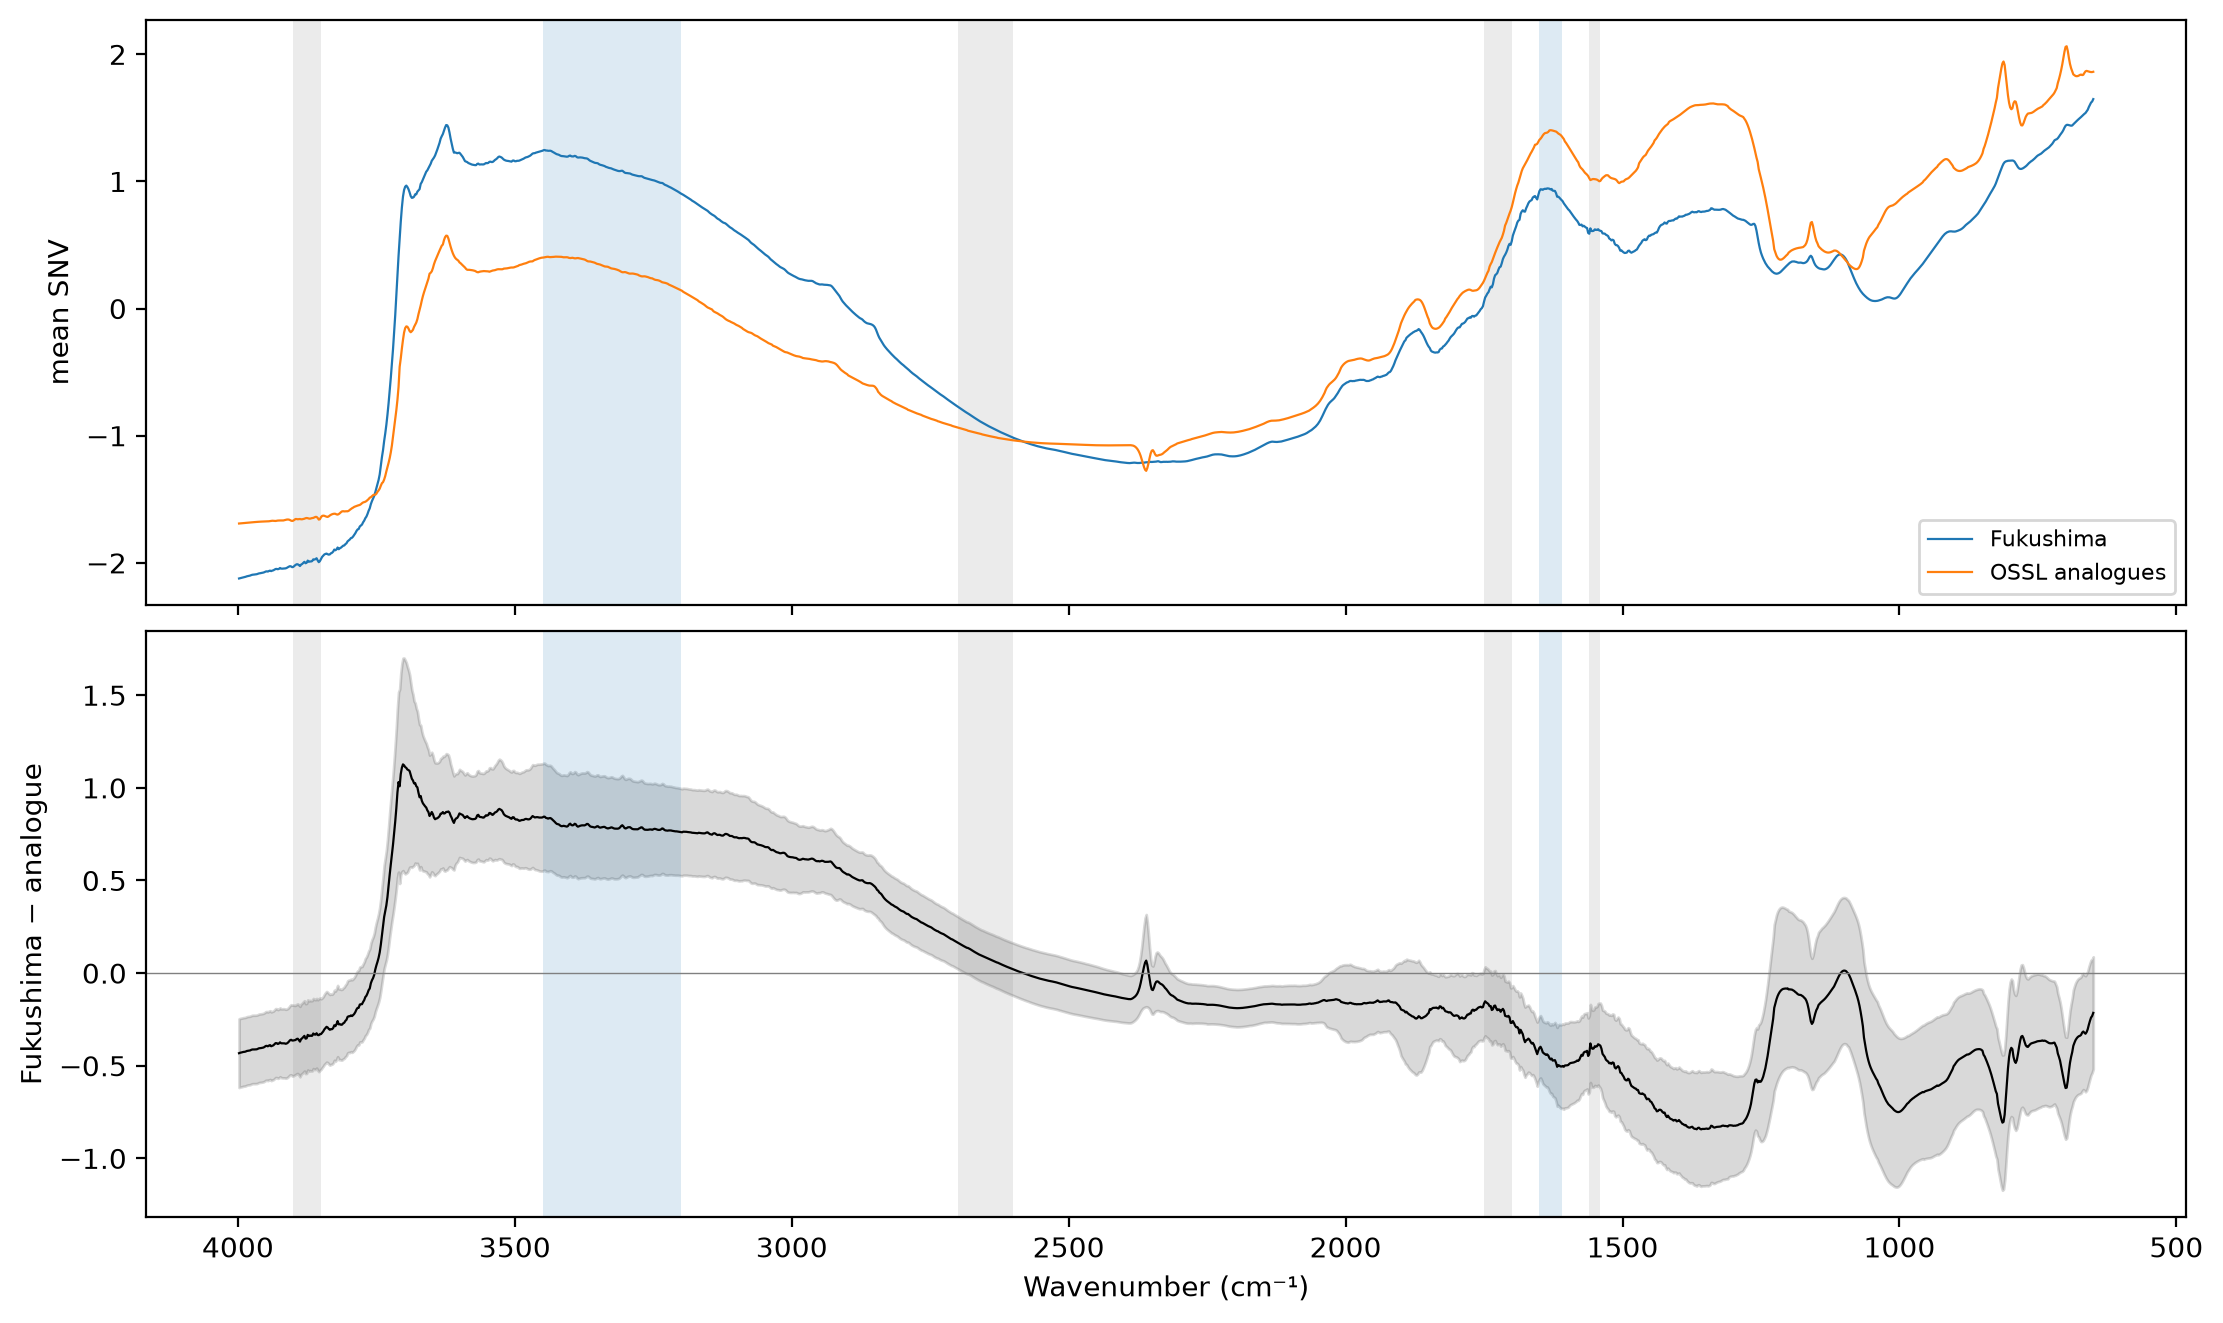

In [ ]:
#| fukudata
diff = Sf_p - Sa
fig, axs = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, layout='constrained')
axs[0].plot(shared_wns, Sf_p.mean(0), lw=0.8, label='Fukushima')
axs[0].plot(shared_wns, Sa.mean(0), lw=0.8, label='OSSL analogues')
axs[1].plot(shared_wns, diff.mean(0), lw=0.8, c='k')
axs[1].fill_between(shared_wns, diff.mean(0) - diff.std(0), diff.mean(0) + diff.std(0), color='k', alpha=0.15)
axs[1].axhline(0, lw=0.5, c='grey')
for ax in axs:
    for band, lo, hi in water_bands.values():
        ax.axvspan(*band, color='tab:blue', alpha=0.15, lw=0)
        for a in (lo, hi): ax.axvspan(*a, color='tab:grey', alpha=0.15, lw=0)
axs[0].set_ylabel('mean SNV'); axs[0].legend(fontsize=8); axs[1].set_ylabel('Fukushima − analogue'); axs[1].invert_xaxis(); axs[1].set_xlabel('Wavenumber (cm⁻¹)');

The mean absolute difference per region, and how consistent its sign is: the share of pairs in which Fukushima is higher, averaged over the region:

In [ ]:
#| fukudata
regions = {'650–1300': (650, 1300), '1300–1610': (1300, 1610), 'H–O–H bend 1610–1650': (1610, 1650), '1650–2000': (1650, 2000), '2000–2800': (2000, 2800),
           '2800–3200': (2800, 3200), 'O–H stretch 3200–3450': (3200, 3450), '3450–3700': (3450, 3700), '3700–3998': (3700, 3998)}
pd.DataFrame({k: {'mean difference': diff[:, (shared_wns >= lo) & (shared_wns <= hi)].mean(), 'mean |difference|': np.abs(diff[:, (shared_wns >= lo) & (shared_wns <= hi)]).mean(),
                  'share Fukushima higher': (diff[:, (shared_wns >= lo) & (shared_wns <= hi)] > 0).mean()} for k, (lo, hi) in regions.items()}).T.round(3)

,mean difference,mean |difference|,share Fukushima higher
650–1300,-0.430,0.505,0.158
1300–1610,-0.654,0.658,0.017
H–O–H bend 1610–1650,-0.459,0.461,0.014
1650–2000,-0.216,0.253,0.147
2000–2800,-0.048,0.168,0.345
2800–3200,0.619,0.619,0.998
O–H stretch 3200–3450,0.789,0.789,0.999
3450–3700,0.874,0.876,0.994
3700–3998,-0.158,0.382,0.212


## Moisture scores

The height of each water band in the Fukushima spectra, their analogues and 10,000 random OSSL spectra. The quantiles, and the share of pairs in which the Fukushima soil has the higher band:

In [ ]:
#| fukudata
hgt = {name: {'Fukushima': band_height(Sf_p, shared_wns, *b), 'analogues': band_height(Sa, shared_wns, *b), 'OSSL': band_height(So, shared_wns, *b)}
       for name, b in water_bands.items()}
qs = [0.05, 0.25, 0.5, 0.75, 0.95]
tab = pd.concat({name: pd.DataFrame({k: np.quantile(v, qs) for k, v in d.items()}, index=qs) for name, d in hgt.items()}, axis=1)
display(tab.round(3))
{name: round(float((d['Fukushima'] > d['analogues']).mean()), 3) for name, d in hgt.items()}

O–H stretch                  H–O–H bend                 
       Fukushima analogues   OSSL  Fukushima analogues   OSSL
0.05       2.308     1.136  0.848      0.330     0.465  0.359
0.25       2.499     1.538  1.407      0.397     0.545  0.513
0.50       2.635     1.717  1.727      0.451     0.594  0.637
0.75       2.728     1.834  1.962      0.501     0.662  0.776
0.95       2.848     2.029  2.198      0.572     0.760  1.009

{'O–H stretch': 0.999, 'H–O–H bend': 0.047}

## Moisture and the transfer failure

The Spearman correlation of the Kex errors with each band height, and with its excess over the analogue's: the zero-shot error of the pretrained OSSL model on all samples, and the residuals of the fully fine-tuned and Fukushima-only models of `06_dynamics` on the test samples:

In [ ]:
#| fukudata
fuku.source = fuku.source.assign(target=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
Xf_d = preprocessings()['snv_d1'].fit_transform(Xf)
is_test = np.isin(idf, cs137_split()[1])
feat = pd.DataFrame({f'{name}{s}': (d['Fukushima'] - d['analogues']) if s else d['Fukushima'] for name, d in hgt.items() for s in ('', ', excess')}, index=fp.index).reindex(idf)
errs = {'zero-shot, all': (predict(load_pretrained('ossl_kex_snv_d1'), Xf_d, shared_wns) - yf, np.ones(len(yf), bool)),
        'fully fine-tuned, test': (predict(tracked_model('dyn_fuku_kex_ft'), Xf_d, shared_wns) - yf, is_test),
        'Fukushima only, test': (predict(tracked_model('dyn_fuku_kex_scratch'), Xf_d, shared_wns) - yf, is_test)}
ok = feat.notna().all(axis=1).to_numpy()
pd.DataFrame({k: {c: spearmanr(e[m & ok], feat[c].to_numpy()[m & ok])[0] for c in feat} for k, (e, m) in errs.items()}).T.round(3)

,O–H stretch,"O–H stretch, excess",H–O–H bend,"H–O–H bend, excess"
"zero-shot, all",0.040,0.066,-0.031,0.062
"fully fine-tuned, test",0.019,0.141,0.003,0.137
"Fukushima only, test",0.009,0.097,0.036,0.117


Zero-shot scores of the pretrained OSSL model on the quarters of the samples with the lowest to the highest O–H stretching band:

In [ ]:
#| fukudata
pz = errs['zero-shot, all'][0] + yf
oh = feat['O–H stretch'].to_numpy()
qt = pd.qcut(oh[ok], 4, labels=['lowest band', '2nd', '3rd', 'highest band'])
yq, pq = yf[ok], pz[ok]
pd.DataFrame({q: {'n': int((qt == q).sum()), 'median height': float(np.median(oh[ok][qt == q])), **scores(yq[qt == q], pq[qt == q])} for q in qt.categories}).T.round(3)

,n,median height,R²,r,RMSE,bias
lowest band,347.0,2.404,-1.151,-0.025,0.598,0.301
2nd,346.0,2.579,-0.732,0.095,0.536,0.263
3rd,346.0,2.684,-0.516,0.268,0.576,0.277
highest band,346.0,2.795,-0.824,0.158,0.621,0.359


## Bruker spectra against their analogues

If the Bruker spectra of the Fukushima soils show the same shift against their OSSL analogues, the shift comes from the sample preparation, which both instruments shared. If they don't, it comes from the Thermo instrument or its accessory.

Every sample with Bruker spectra and all seven properties gets its OSSL analogue, matched as above. All of them also have Thermo spectra. The Bruker exports end at 3996 cm⁻¹, so all spectra here use 650–3996 cm⁻¹. Their Thermo spectra are compared with the same analogues. The mean difference per region, and the share of pairs in which the Fukushima spectrum is higher:

In [ ]:
#| fukudata
pw = shared_wns[:-1]
b_ids = [i for i in sorted(bruker_files(), key=int) if i not in excluded]
bp = prop_features(fuku_shared_props(b_ids))
b_ids = list(bp.index)
b_an = op.index[NearestNeighbors(n_neighbors=1).fit(sc_p.transform(op)).kneighbors(sc_p.transform(bp))[1][:, 0]]
Sb = snv.fit_transform(load_bruker(pw, b_ids).spectra)
Sba = snv.fit_transform(om.spectra[opos[b_an].to_numpy()][:, :-1])
paired = [i for i in b_ids if i in set(spa_files())]
pm = np.isin(b_ids, paired)
St = snv.fit_transform(load_fuku(pw, paired).spectra)
test_eq(pm.all(), True)
sets = {'Bruker': Sb - Sba, 'Thermo': St - Sba}
rw = {k: (lo, min(hi, pw[-1])) for k, (lo, hi) in regions.items()}
res = {}
for k, d in sets.items():
    for reg, (lo, hi) in rw.items():
        m = (pw >= lo) & (pw <= hi)
        res[k, 'mean difference'] = res.get((k, 'mean difference'), {}) | {reg: d[:, m].mean()}
        res[k, 'share higher'] = res.get((k, 'share higher'), {}) | {reg: (d[:, m] > 0).mean()}
print({k: len(d) for k, d in sets.items()})
pd.DataFrame(res).round(3)

{'Bruker': 375, 'Thermo': 375}


Bruker                       Thermo             
                      mean difference share higher mean difference share higher
650–1300                        0.120        0.618          -1.837        0.010
1300–1610                      -0.299        0.153          -0.942        0.013
H–O–H bend 1610–1650           -0.148        0.213          -0.578        0.010
1650–2000                      -0.252        0.107          -0.194        0.208
2000–2800                      -0.089        0.141           0.374        0.905
2800–3200                       0.082        0.710           1.095        0.999
O–H stretch 3200–3450           0.207        0.814           1.291        1.000
3450–3700                       0.292        0.866           1.403        0.997
3700–3998                       0.076        0.675           0.571        0.860

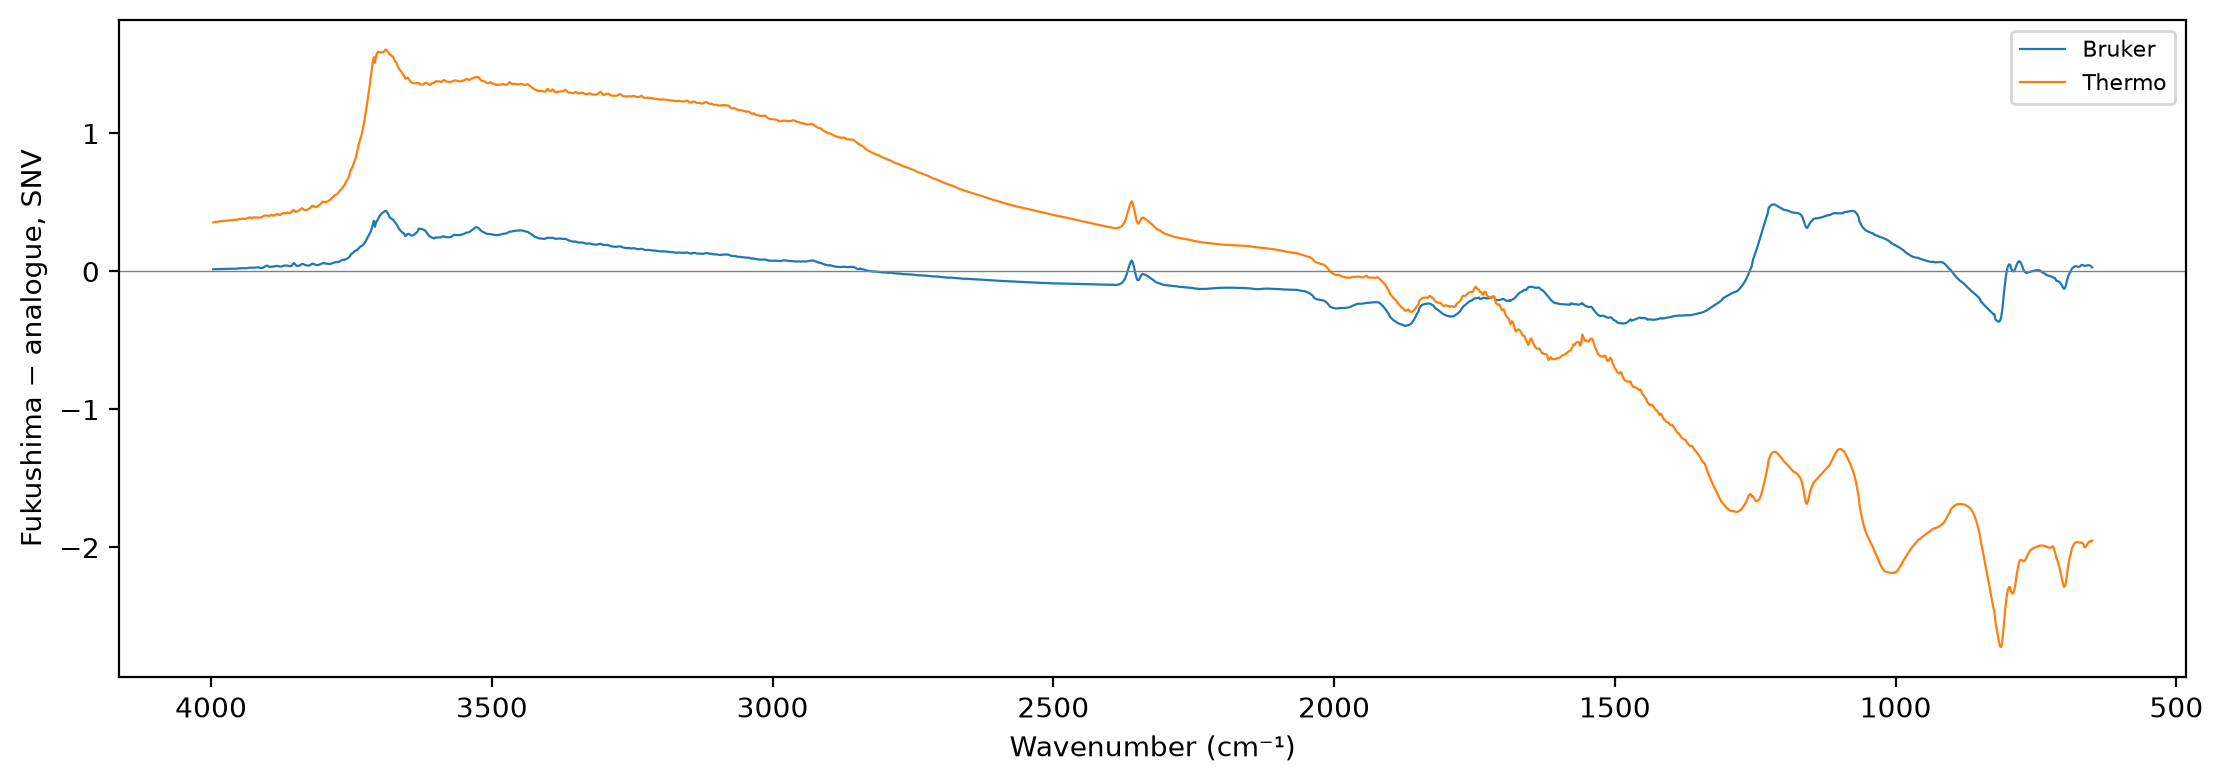

In [ ]:
#| fukudata
fig, ax = plt.subplots(figsize=(11, 3.8), layout='constrained')
for k, d in sets.items(): ax.plot(pw, d.mean(0), lw=0.8, label=k)
ax.axhline(0, lw=0.5, c='grey')
ax.set_ylabel('Fukushima − analogue, SNV'); ax.invert_xaxis(); ax.set_xlabel('Wavenumber (cm⁻¹)'); ax.legend(fontsize=8);

## Findings

Compared with their OSSL soil analogues, the Fukushima spectra differ by a broad, systematic shift of intensity between regions. After SNV, Fukushima is higher between 2800 and 3700 cm⁻¹ in almost every pair: by 0.62 on average between 2800 and 3200 cm⁻¹, 0.79 in the O–H stretching band (3200–3450 cm⁻¹) and 0.87 between 3450 and 3700 cm⁻¹, in 99 to 100% of the pairs. It is lower below 2000 cm⁻¹: by 0.43 between 650 and 1300 cm⁻¹ and 0.65 between 1300 and 1610 cm⁻¹, in 84 to 98% of the pairs. The 1,385 pairs use 831 distinct OSSL analogues.

This pattern doesn't look like water in the samples. Water would raise both water bands. The O–H stretching band is higher than in the analogue for 99.9% of the Fukushima soils (median height 2.64 against 1.72), but the H–O–H bending band is higher for only 4.7% (median 0.45 against 0.59). SNV makes every difference relative: a large rise in one region lowers the rest after normalisation. So a lower bending band doesn't rule out some water, but the two bands don't move together as water would make them.

Neither band explains the Kex errors. Their Spearman correlations with the zero-shot error of the OSSL model, and with the residuals of the fully fine-tuned and Fukushima-only models, are at most 0.14 in absolute value. The largest are for the excess over the analogue, with the fine-tuned model's residuals (0.14 for both bands). By quarters of the O–H stretching band, the zero-shot correlation is −0.03, 0.10, 0.27 and 0.16, without a steady trend.

The systematic shift towards the 2800–3700 cm⁻¹ region, present in nearly every Fukushima spectrum, is the largest difference from matched OSSL soils found so far. It fits a difference in measurement mode or sample preparation, such as particle size, dilution or the accessory, which changes the relative intensity of strong and weak bands. That is an interpretation, not a test. A shift that is the same in every spectrum adds a constant to a linear model's predictions and leaves their ranking unchanged. The analogue EPO in `13_epo` estimated its directions from uncentred pair differences, so they include this shift, and removing them did not give the ridge regression a usable correlation. A CNN is not linear, so the shift can change its ranking. This notebook doesn't test that.

The shift comes mainly from the Thermo measurement. For the 375 soils with both Bruker and Thermo spectra and all seven properties, the Thermo spectra show the shift against their OSSL analogues even more strongly than the current selection: +1.29 in the O–H stretching band and −1.84 between 650 and 1300 cm⁻¹, in 99 to 100% of the pairs. The Bruker spectra of the same soils, against the same analogues, show a much weaker shift towards high wavenumbers: +0.21 in the O–H stretching band (higher in 81% of the pairs), and +0.12 between 650 and 1300 cm⁻¹, the opposite sign to Thermo. 316 of these soils are Kazu samples, outside the current selection. Whether the two instruments measured the same prepared material is not known.

The OSSL Kex model fails zero-shot on these Bruker spectra too (correlation 0.19, `05_paired`), although they show little of the shift. So the shift is not the whole cause of the Kex failure.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()